In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_TyanglaphatLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,44.470001,%,2025-10-14 11:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-10-14,11:45:00
1,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,37.172519,%,2025-10-14 12:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-10-14,12:45:00
2,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,34.310000,%,2025-10-14 13:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-10-14,13:45:00
3,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,35.213500,%,2025-10-14 14:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-10-14,14:45:00
4,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,37.111125,%,2025-10-14 15:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-10-14,15:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,58.105000,%,2025-12-03 06:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-12-03,06:45:00
996,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,58.557833,%,2025-12-03 07:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-12-03,07:45:00
997,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,56.699833,%,2025-12-03 08:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-12-03,08:45:00
998,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,53.405500,%,2025-12-03 09:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2025-12-03,09:45:00


In [3]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [4]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-10-14,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,44.49,13
1,2025-10-15,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,47.35,24
2,2025-10-16,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,47.94,24
3,2025-10-17,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.77,24
4,2025-10-18,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.19,24
5,2025-10-19,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.85,24
6,2025-10-20,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,53.66,10
7,2025-10-26,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,32.02,9
8,2025-10-27,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,40.47,24
9,2025-10-28,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,53.08,24


/tmp/ipykernel_54041/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


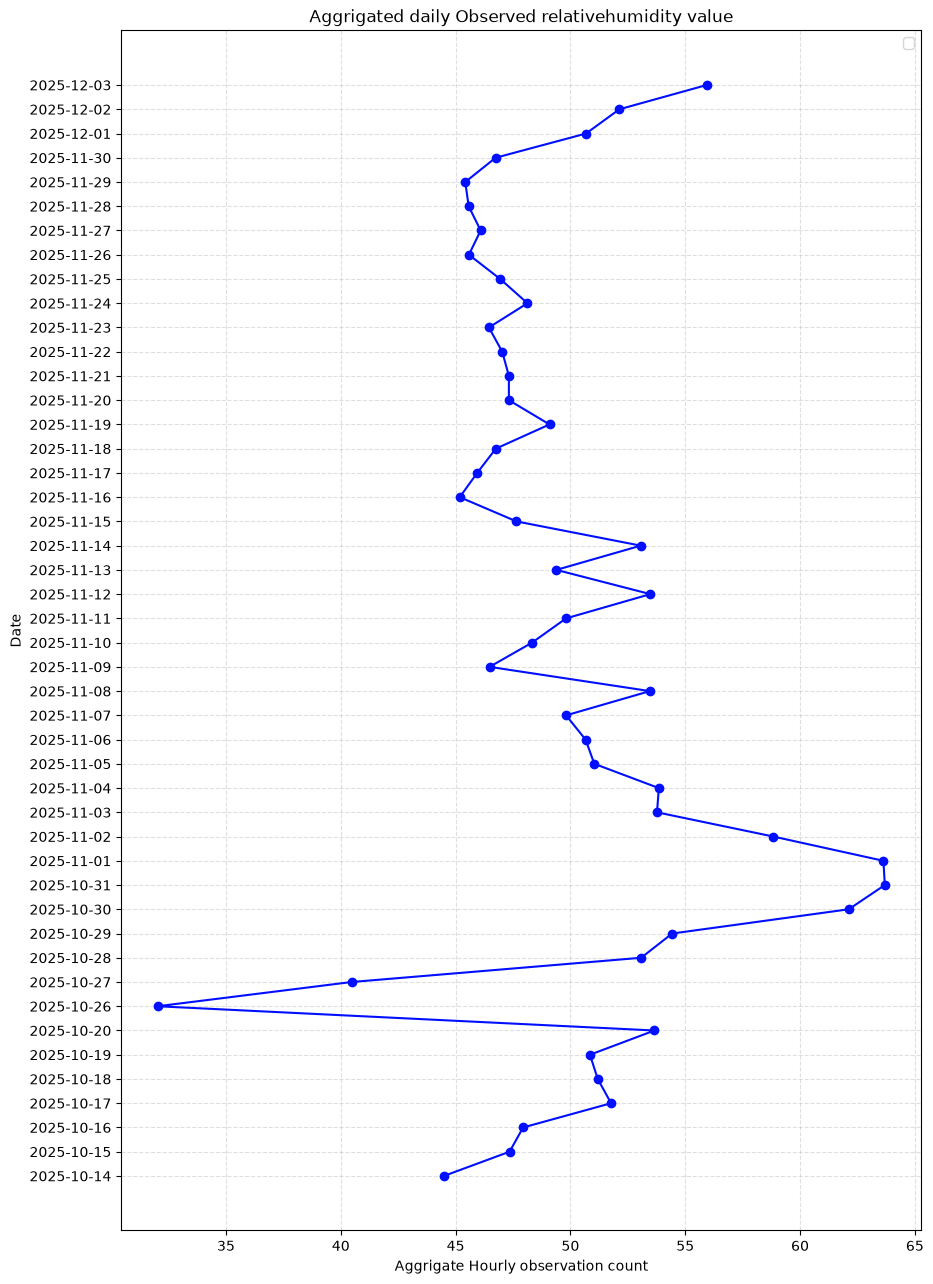

In [5]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [6]:
df30 = pd.read_csv('cleaned_TyanglaphatLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,56.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,55.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,49.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,49.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
714,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,50.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
715,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,51.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
716,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
717,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [7]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [8]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,49.56,18
1,2026-09-13,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.00,24
2,2026-09-14,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.38,24
3,2026-09-15,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.71,24
4,2026-09-16,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.75,24
5,2026-09-17,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.79,24
6,2026-09-18,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.58,24
7,2026-09-19,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.96,24
8,2026-09-20,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.29,24
9,2026-09-21,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.54,24


/tmp/ipykernel_54041/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


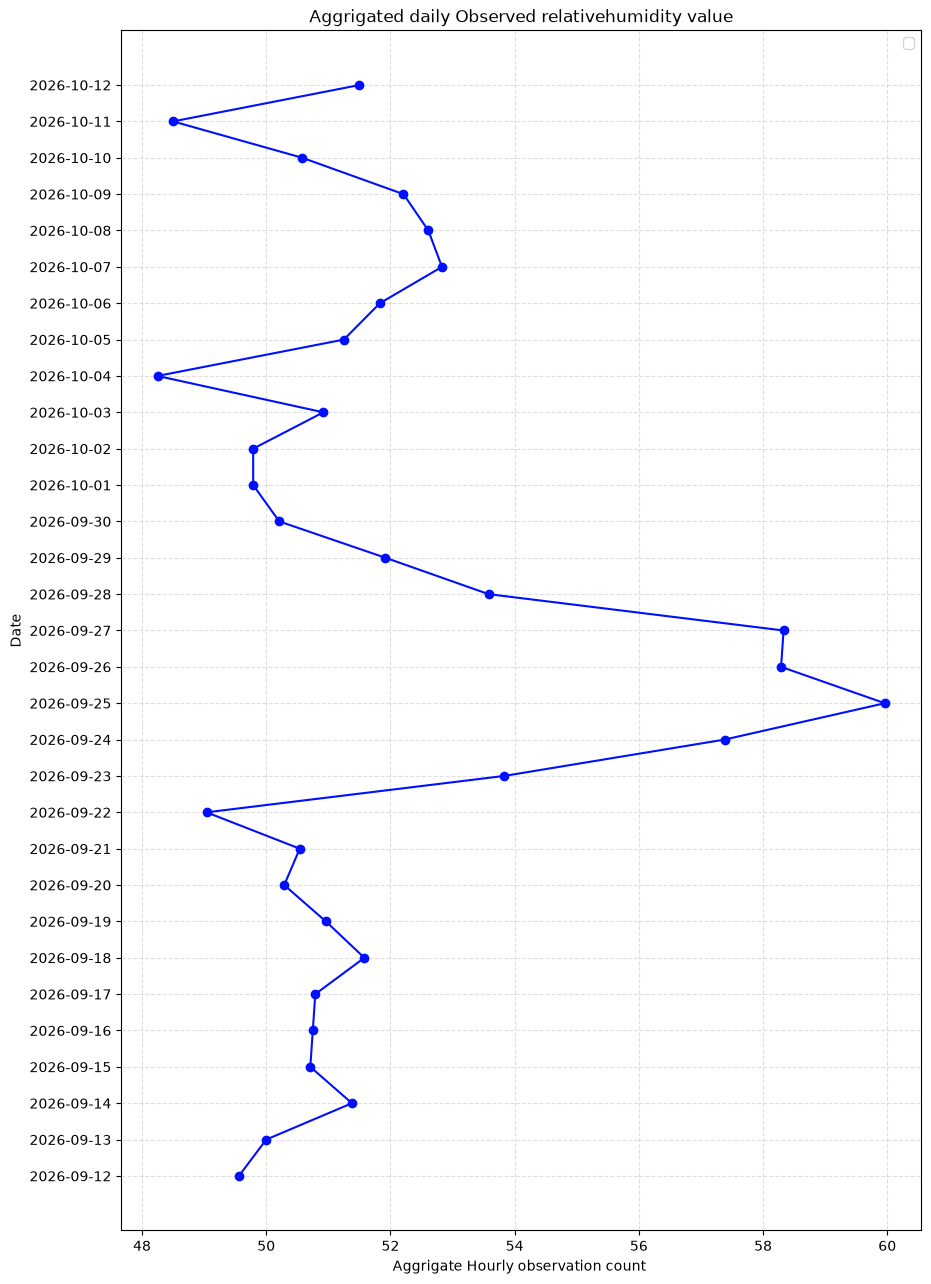

In [9]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [10]:
df7 = pd.read_csv('cleaned_TyanglaphatLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,54.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,53.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,51.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,50.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,47.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
162,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,50.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
163,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,51.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
164,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
165,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [11]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [12]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.17,18
1,2026-10-06,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.83,24
2,2026-10-07,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,52.83,24
3,2026-10-08,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,52.61,23
4,2026-10-09,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,52.21,24
5,2026-10-10,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,50.58,24
6,2026-10-11,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,48.50,24
7,2026-10-12,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,51.50,6


/tmp/ipykernel_54041/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


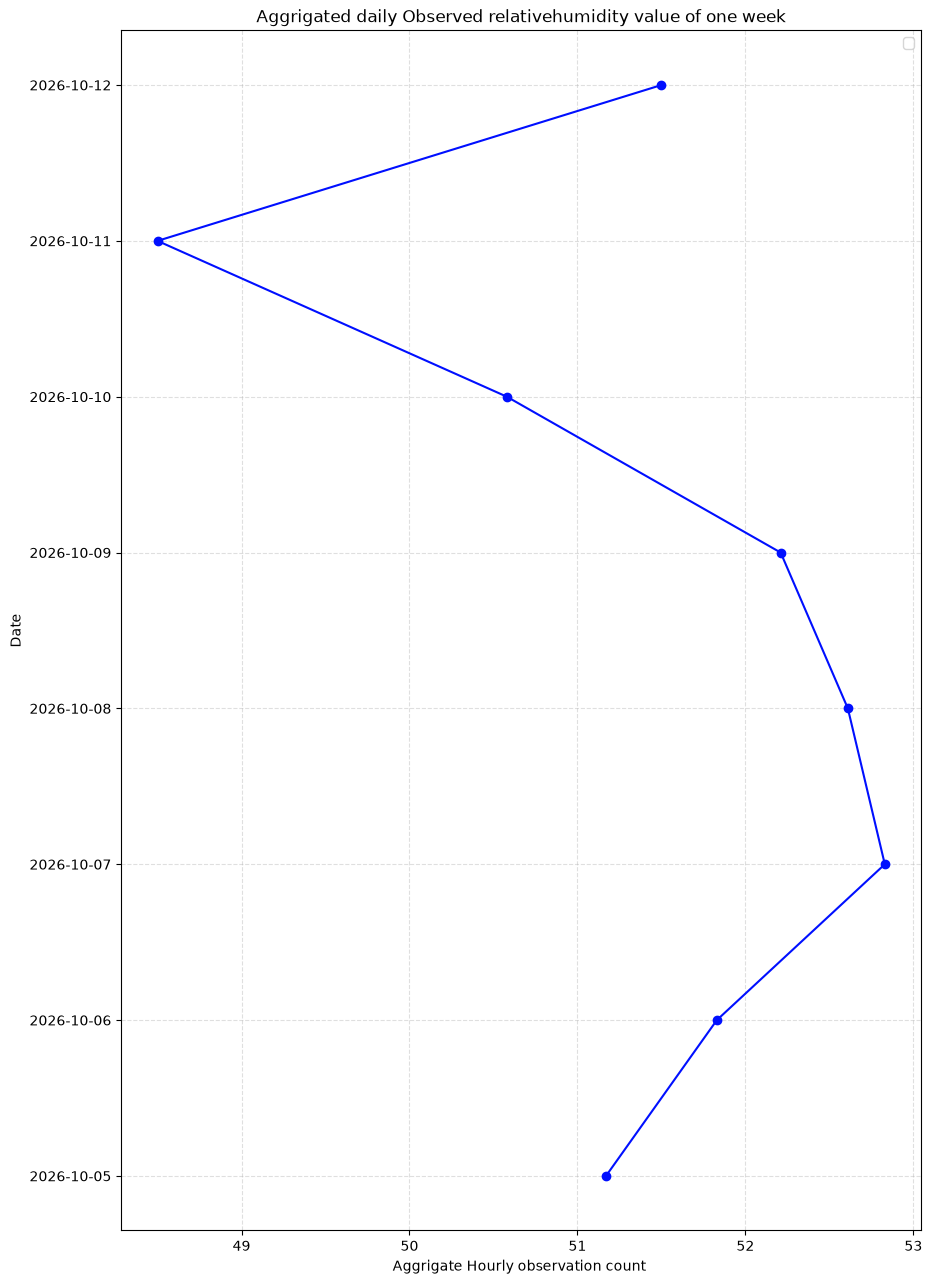

In [13]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [14]:
df24 = pd.read_csv('cleaned_TyanglaphantLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,54.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,54.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,52.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,51.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,50.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,44.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,43.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,42.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,42.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6094777,Tyanglaphat (SC - 21) - GD Labs,relativehumidity,42.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.686165,85.28026,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [15]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_54041/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


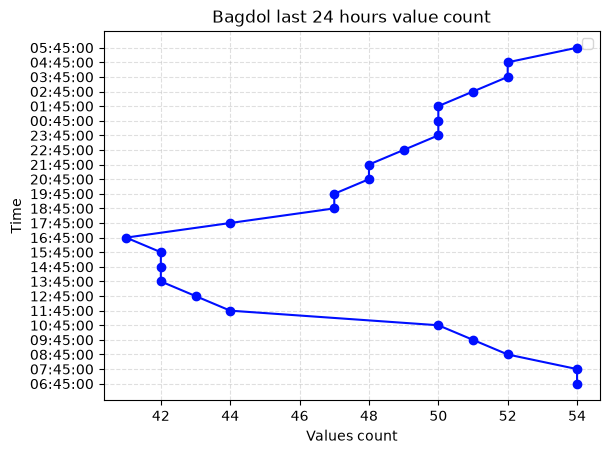

In [16]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()